# Mini Project 2026 — Modelling a 3D Printer

* **Course:** SC42155 - Modelling of Dynamical Systems
* **Group:** 17

| Student Name | Email | Student ID |
| :--- | :--- | :--- |
| Irene Chen Cordero León | icorderoleon@tudelft.nl | 6721486 |
| Elif Tunç | eliftunc@tudelft.nl | 6649459 |

This notebook contains the derivations and simulations for Q1.1–Q3.2. Each question starts with the model and assumptions, followed by the code and plots needed to check the result. Parameters introduced for numerical examples are identified separately from the symbolic model.

## Part 1 — Physical modelling

We first derive the CoreXY motion and motor dynamics, then use these results to generate two paths. The nozzle and deposited-filament temperature models are treated separately.


In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid

sp.init_printing()
plt.rcParams.update({'figure.figsize': (7, 4.5), 'axes.grid': True})

---
# Q1.1 — Kinematics

In the CoreXY mechanism, both motors contribute to both Cartesian coordinates. Positive motor rotations and the coordinate origin follow the mechanism diagram. The effective belt displacement per radian is the motor pulley radius $r_m$.

The belt constraints give

$$\boxed{x=\frac{r_m}{2}(\theta_l+\theta_r)},\qquad
\boxed{y=\frac{r_m}{2}(\theta_l-\theta_r)}.$$

The factors of $1/2$ follow from the CoreXY belt routing: a Cartesian displacement corresponds to the combined motion of the two belts. Constant coordinate offsets can be added without affecting velocity or dynamics.

Differentiate with respect to time:

$$\boxed{\dot x=\frac{r_m}{2}(\dot\theta_l+\dot\theta_r)},\qquad
\boxed{\dot y=\frac{r_m}{2}(\dot\theta_l-\dot\theta_r)}.$$

In matrix form, with $\boldsymbol\theta=[\theta_l,\theta_r]^T$,

$$\begin{bmatrix}x\\y\end{bmatrix}=
\underbrace{\frac{r_m}{2}\begin{bmatrix}1&1\\1&-1\end{bmatrix}}_{J_k}
\begin{bmatrix}\theta_l\\\theta_r\end{bmatrix},\qquad
\begin{bmatrix}\dot x\\\dot y\end{bmatrix}=J_k
\begin{bmatrix}\dot\theta_l\\\dot\theta_r\end{bmatrix}.$$

The inverse transformation is

$$\theta_l=\frac{x+y}{r_m},\qquad\theta_r=\frac{x-y}{r_m}.$$

In [2]:
theta_l, theta_r, rm = sp.symbols('theta_l theta_r r_m', real=True)
omega_l, omega_r = sp.symbols('omega_l omega_r', real=True)
Jk = rm/2 * sp.Matrix([[1, 1], [1, -1]])
q = sp.simplify(Jk * sp.Matrix([theta_l, theta_r]))
v = sp.simplify(Jk * sp.Matrix([omega_l, omega_r]))
print('Position [x, y]:'); sp.pprint(q)
print('Velocity [xdot, ydot]:'); sp.pprint(v)
print('Inverse kinematics:'); sp.pprint(sp.simplify(Jk.inv() * sp.Matrix(sp.symbols('x y'))))

Position [x, y]:
⎡rₘ⋅(θₗ + θᵣ)⎤
⎢────────────⎥
⎢     2      ⎥
⎢            ⎥
⎢rₘ⋅(θₗ - θᵣ)⎥
⎢────────────⎥
⎣     2      ⎦
Velocity [xdot, ydot]:
⎡rₘ⋅(ωₗ + ωᵣ)⎤
⎢────────────⎥
⎢     2      ⎥
⎢            ⎥
⎢rₘ⋅(ωₗ - ωᵣ)⎥
⎢────────────⎥
⎣     2      ⎦
Inverse kinematics:
⎡x + y⎤
⎢─────⎥
⎢ rₘ  ⎥
⎢     ⎥
⎢x - y⎥
⎢─────⎥
⎣ rₘ  ⎦


### CoreXY coordinate diagram

The diagram illustrates the chosen signs and the relation between motor rotation and Cartesian displacement.

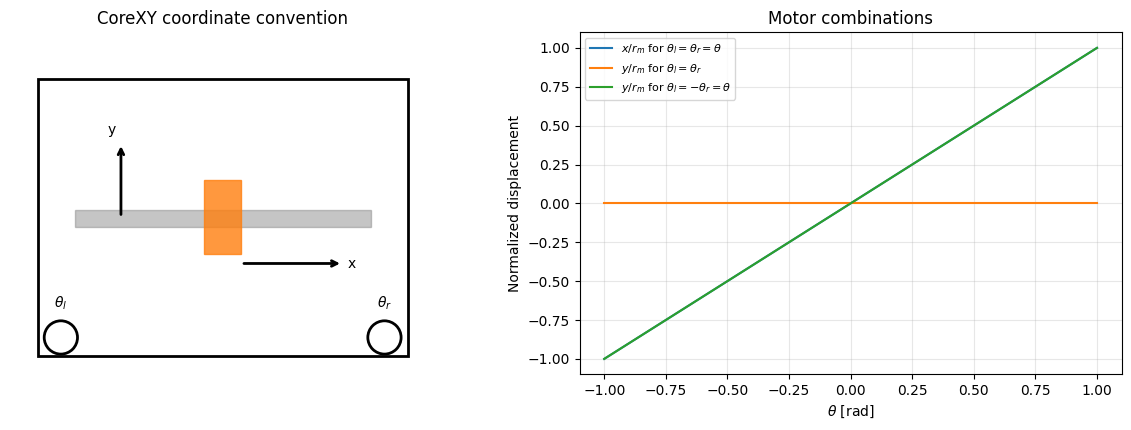

In [3]:
from matplotlib.patches import Rectangle, Circle, FancyArrowPatch
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
ax = axes[0]
ax.add_patch(Rectangle((0,0), 4,3, fill=False, linewidth=2))
ax.add_patch(Rectangle((0.4,1.4),3.2,.18,color='gray',alpha=.45))
ax.add_patch(Rectangle((1.8,1.1),.4,.8,color='tab:orange',alpha=.8))
for px,lab in [(0.25,r'$\theta_l$'),(3.75,r'$\theta_r$')]:
    ax.add_patch(Circle((px,.2),.18,fill=False,linewidth=2))
    ax.text(px,.52,lab,ha='center')
ax.annotate('',xy=(3.3,1.0),xytext=(2.2,1.0),arrowprops=dict(arrowstyle='->',lw=2))
ax.annotate('',xy=(.9,2.3),xytext=(.9,1.5),arrowprops=dict(arrowstyle='->',lw=2))
ax.text(3.35,.95,'x');ax.text(.75,2.4,'y')
ax.set(xlim=(-.3,4.3),ylim=(-.2,3.5),title='CoreXY coordinate convention')
ax.set_aspect('equal');ax.axis('off')
qnorm=np.linspace(-1,1,201)
axes[1].plot(qnorm,qnorm,label=r'$x/r_m$ for $\theta_l=\theta_r=\theta$')
axes[1].plot(qnorm,.5*qnorm*0,label=r'$y/r_m$ for $\theta_l=\theta_r$')
axes[1].plot(qnorm,qnorm,label=r'$y/r_m$ for $\theta_l=-\theta_r=\theta$')
axes[1].set(xlabel=r'$\theta$ [rad]',ylabel='Normalized displacement',title='Motor combinations')
axes[1].grid(alpha=.3);axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()

---
# Q1.2 — Dynamics with voltage-controlled DC motors

The motor circuit consists of inductance $L_m$, resistance $R_m$, and the motor's electromechanical coupling. The shaft is rigid and mechanical friction is neglected.

For either motor $j\in\{l,r\}$, Kirchhoff's voltage law gives

$$u_j=L_m\dot i_j+R_m i_j+K_m\dot\theta_j.$$

The last term is the back-EMF. The electromagnetic torque is $\tau_j=K_m i_j$ (SI-consistent torque and back-EMF constants).

## Mechanical energy and equivalent inertia

The print head has mass $m$ and Cartesian speed $\dot x^2+\dot y^2$. The motors each have rotor inertia $J_m$. Therefore

$$\mathcal T=\frac12J_m(\dot\theta_l^2+\dot\theta_r^2)+\frac12m(\dot x^2+\dot y^2).$$

Substituting Q1.1,

$$\dot x^2+\dot y^2=\frac{r_m^2}{2}(\dot\theta_l^2+\dot\theta_r^2).$$

Thus

$$\mathcal T=\frac12\underbrace{\left(J_m+\frac{mr_m^2}{2}\right)}_{J_{\rm eq}}
(\dot\theta_l^2+\dot\theta_r^2),\qquad
\boxed{J_{\rm eq}=J_m+\frac{mr_m^2}{2}}.$$

With no friction or external mechanical load, the torque balance for each motor is

$$\boxed{J_{\rm eq}\ddot\theta_j=K_m i_j}.$$

Define the six-dimensional state and two motor-voltage inputs:

$$\mathbf z=[\theta_l,\theta_r,\omega_l,\omega_r,i_l,i_r]^T,\quad
\mathbf u=[u_l,u_r]^T,\quad \omega_j=\dot\theta_j.$$

The state equations are

$$\boxed{\dot{\mathbf z}=\begin{bmatrix}
\omega_l\\\omega_r\\K_m i_l/J_{\rm eq}\\K_m i_r/J_{\rm eq}\\
(u_l-R_m i_l-K_m\omega_l)/L_m\\
(u_r-R_m i_r-K_m\omega_r)/L_m
\end{bmatrix}}.$$

Viscous and Coulomb friction are excluded from the model.

In [4]:
Jm, m, Lm, Rm, Km = sp.symbols('J_m m L_m R_m K_m', positive=True)
Jeq = Jm + m*rm**2/2
ul, ur, il, ir = sp.symbols('u_l u_r i_l i_r', real=True)
z = sp.Matrix([theta_l, theta_r, omega_l, omega_r, il, ir])
f = sp.Matrix([
    omega_l, omega_r, Km*il/Jeq, Km*ir/Jeq,
    (ul-Rm*il-Km*omega_l)/Lm,
    (ur-Rm*ir-Km*omega_r)/Lm
])
A = sp.simplify(f.jacobian(z))
B = sp.simplify(f.jacobian(sp.Matrix([ul,ur])))
print('Equivalent inertia:'); sp.pprint(Jeq)
print('State matrix A:'); sp.pprint(A)
print('Input matrix B:'); sp.pprint(B)
assert sp.simplify(f - A*z - B*sp.Matrix([ul,ur])) == sp.zeros(6,1)

Equivalent inertia:
         2
     m⋅rₘ 
Jₘ + ─────
       2  
State matrix A:
⎡0  0   1     0         0             0      ⎤
⎢                                            ⎥
⎢0  0   0     1         0             0      ⎥
⎢                                            ⎥
⎢                      2⋅Kₘ                  ⎥
⎢0  0   0     0    ────────────       0      ⎥
⎢                             2              ⎥
⎢                  2⋅Jₘ + m⋅rₘ               ⎥
⎢                                            ⎥
⎢                                    2⋅Kₘ    ⎥
⎢0  0   0     0         0        ────────────⎥
⎢                                           2⎥
⎢                                2⋅Jₘ + m⋅rₘ ⎥
⎢                                            ⎥
⎢      -Kₘ             -Rₘ                   ⎥
⎢0  0  ────   0        ────           0      ⎥
⎢       Lₘ              Lₘ                   ⎥
⎢                                            ⎥
⎢            -Kₘ                     -Rₘ     ⎥
⎢0  0   0    ────       0  

### Motor model diagram and state coupling

The motor diagram summarizes the electromechanical coupling. The matrix plot indicates the nonzero entries of the symbolic state matrix.

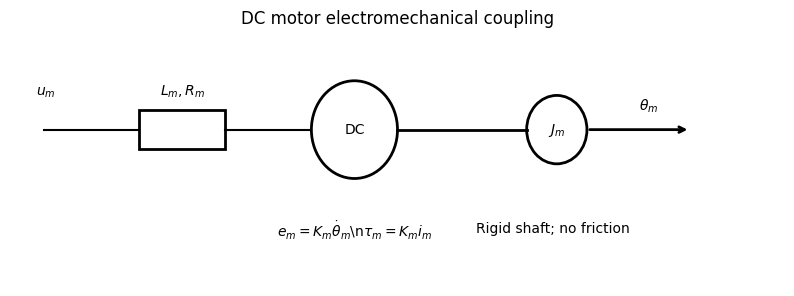

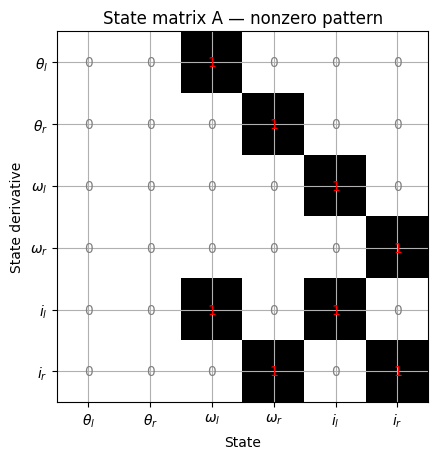

In [5]:
from matplotlib.patches import Rectangle, Circle
fig,ax=plt.subplots(figsize=(10,3.3))
ax.plot([.4,1.5],[2,2],color='black');ax.plot([2.5,3.5],[2,2],color='black')
ax.add_patch(Rectangle((1.5,1.8),1,.4,fill=False,lw=2))
ax.text(2,2.35,r'$L_m, R_m$',ha='center')
ax.add_patch(Circle((4,2),.5,fill=False,lw=2))
ax.text(4,2,'DC',ha='center',va='center')
ax.plot([4.5,6],[2,2],color='black',lw=2)
ax.add_patch(Circle((6.35,2),.35,fill=False,lw=2))
ax.text(6.35,2,r'$J_m$',ha='center',va='center')
ax.annotate('',xy=(7.9,2),xytext=(6.7,2),arrowprops=dict(arrowstyle='->',lw=2))
ax.text(7.3,2.2,r'$\theta_m$')
ax.text(.3,2.35,r'$u_m$');ax.text(4,.9,r'$e_m=K_m\dot\theta_m$\n$\tau_m=K_m i_m$',ha='center')
ax.text(6.3,.95,'Rigid shaft; no friction',ha='center')
ax.set(xlim=(0,9),ylim=(.4,3),title='DC motor electromechanical coupling')
ax.axis('off');plt.show()
state_names=[r'$\theta_l$',r'$\theta_r$',r'$\omega_l$',r'$\omega_r$',r'$i_l$',r'$i_r$']
sparsity=np.array([[int(not sp.simplify(A[i,j]).equals(0)) for j in range(6)] for i in range(6)])
fig,ax=plt.subplots(figsize=(5.7,4.7))
ax.imshow(sparsity,cmap='Greys',vmin=0,vmax=1)
ax.set_xticks(range(6),state_names);ax.set_yticks(range(6),state_names)
ax.set(xlabel='State',ylabel='State derivative',title='State matrix A — nonzero pattern')
for i in range(6):
    for j in range(6):
        ax.text(j,i,str(sparsity[i,j]),ha='center',va='center',color='red' if sparsity[i,j] else 'gray')
plt.tight_layout();plt.show()

---
# Q1.3 — Decouple the $x$ and $y$ dynamics

The kinematics suggest using **sum and difference** coordinates. Introduce

$$i_x=i_l+i_r,\quad i_y=i_l-i_r,\qquad
u_x=u_l+u_r,\quad u_y=u_l-u_r.$$

$u_x$ and $u_y$ are transformed voltage inputs; $u_l$ and $u_r$ are the motor voltages.

Using $x=r_m(\theta_l+\theta_r)/2$ and $y=r_m(\theta_l-\theta_r)/2$,

$$\boxed{\ddot x=\frac{r_mK_m}{2J_{\rm eq}}i_x},\qquad
\boxed{\ddot y=\frac{r_mK_m}{2J_{\rm eq}}i_y}.$$

Adding and subtracting the two motor electrical equations gives

$$\boxed{L_m\dot i_x=u_x-R_m i_x-\frac{2K_m}{r_m}\dot x},$$
$$\boxed{L_m\dot i_y=u_y-R_m i_y-\frac{2K_m}{r_m}\dot y}.$$

Therefore, choosing $\mathbf x_x=[x,\dot x,i_x]^T$ and $\mathbf x_y=[y,\dot y,i_y]^T$,

$$\boxed{\dot{\mathbf x}_x=
\begin{bmatrix}0&1&0\\0&0&\frac{r_mK_m}{2J_{\rm eq}}\\0&-\frac{2K_m}{r_mL_m}&-\frac{R_m}{L_m}\end{bmatrix}\mathbf x_x+
\begin{bmatrix}0\\0\\1/L_m\end{bmatrix}u_x}$$

and identically for $y$ with $x\to y$, $i_x\to i_y$, $u_x\to u_y$.

To recover actual motor voltages,

$$\boxed{u_l=\frac{u_x+u_y}{2}},\qquad
\boxed{u_r=\frac{u_x-u_y}{2}}.$$

Thus the two Cartesian axes are decoupled in the ideal symmetric model.

In [6]:
ux, uy = sp.symbols('u_x u_y', real=True)
ix, iy = sp.symbols('i_x i_y', real=True)
xd, yd = sp.symbols('xdot ydot', real=True)
Ad = sp.Matrix([[0,1,0],[0,0,rm*Km/(2*Jeq)],
                [0,-2*Km/(rm*Lm),-Rm/Lm]])
Bd = sp.Matrix([0,0,1/Lm])
print('Decoupled state matrix:'); sp.pprint(Ad)
print('Decoupled input vector:'); sp.pprint(Bd)
assert sp.simplify((ux+uy)/2 + (ux-uy)/2 - ux) == 0

Decoupled state matrix:
⎡0    1          0      ⎤
⎢                       ⎥
⎢              Kₘ⋅rₘ    ⎥
⎢0    0     ────────────⎥
⎢                      2⎥
⎢           2⋅Jₘ + m⋅rₘ ⎥
⎢                       ⎥
⎢   -2⋅Kₘ       -Rₘ     ⎥
⎢0  ──────      ────    ⎥
⎣   Lₘ⋅rₘ        Lₘ     ⎦
Decoupled input vector:
⎡0 ⎤
⎢  ⎥
⎢0 ⎥
⎢  ⎥
⎢1 ⎥
⎢──⎥
⎣Lₘ⎦


---
# Q1.4 — Trajectory design

We design **two closed reference paths**: (i) an ellipse and (ii) an original four-leaf clover. The required inputs are obtained by **inverse dynamics** rather than by assuming that sinusoidal motor voltages automatically produce sinusoidal positions.

From Q1.3,

$$i_x=\frac{2J_{\rm eq}}{r_mK_m}\ddot x,\qquad
\dot i_x=\frac{2J_{\rm eq}}{r_mK_m}\dddot x.$$

Substituting in the electrical equation,

$$\boxed{u_x=a\dddot x_d+b\ddot x_d+c\dot x_d},\qquad
\boxed{u_y=a\dddot y_d+b\ddot y_d+c\dot y_d},$$

where

$$a=\frac{2L_mJ_{\rm eq}}{r_mK_m},\quad
b=\frac{2R_mJ_{\rm eq}}{r_mK_m},\quad
c=\frac{2K_m}{r_m}.$$

## Ellipse

$$\boxed{x_d=x_c+A_e\cos(\omega t),\qquad y_d=y_c+B_e\sin(\omega t)}.$$

Its period is $2\pi/\omega$. The amplitudes must fit the print area. Its first three derivatives are used to generate the voltage inputs.

## Four-leaf clover

A four-petal rose can be written as $r=C\sin(2\phi)$, $\phi=\omega t$:

$$\boxed{x_d=x_c+\frac C2[\sin(3\omega t)+\sin(\omega t)]},$$
$$\boxed{y_d=y_c+\frac C2[\cos(\omega t)-\cos(3\omega t)]}.$$

Both paths are smooth and closed. The clover contains a third harmonic, which increases the acceleration/jerk requirements. An ideal instantaneous turn through a sharp corner at nonzero speed would require unbounded acceleration; rounding corners or slowing down avoids this.

The simulations use trajectory-consistent initial position, velocity, and current. Tracking is evaluated for the ideal model without feedback.

In [8]:
t = sp.symbols('t', real=True)
xc, yc, Ae, Be, C, w = sp.symbols('x_c y_c A_e B_e C omega', real=True)
a = 2*Lm*Jeq/(rm*Km)
b = 2*Rm*Jeq/(rm*Km)
c = 2*Km/rm
trajectories = {
    'Ellipse': (xc+Ae*sp.cos(w*t), yc+Be*sp.sin(w*t)),
    'Four-leaf clover': (xc+C/2*(sp.sin(3*w*t)+sp.sin(w*t)),
                         yc+C/2*(sp.cos(w*t)-sp.cos(3*w*t)))
}
reference = {}
for name,(x_des,y_des) in trajectories.items():
    derivatives = [sp.Matrix([sp.diff(x_des,t,k),sp.diff(y_des,t,k)])
                   for k in range(4)]
    voltage_xy = sp.simplify(a*derivatives[3]+b*derivatives[2]+c*derivatives[1])
    voltage_motors = sp.simplify(sp.Matrix([(voltage_xy[0]+voltage_xy[1])/2,
                                            (voltage_xy[0]-voltage_xy[1])/2]))
    reference[name] = {'derivatives': derivatives, 'voltage_xy': voltage_xy,
                       'voltage_motors': voltage_motors}
    print('\n'+name+' — Cartesian inputs:')
    sp.pprint(voltage_xy)
    print('Motor voltages are (u_x+u_y)/2 and (u_x-u_y)/2.')


Ellipse — Cartesian inputs:
⎡     ⎛      2              ⎛           2⎞                              ⎞⎤
⎢Aₑ⋅ω⋅⎝- 2⋅Kₘ ⋅sin(ω⋅t) + ω⋅⎝2⋅Jₘ + m⋅rₘ ⎠⋅(Lₘ⋅ω⋅sin(ω⋅t) - Rₘ⋅cos(ω⋅t))⎠⎥
⎢────────────────────────────────────────────────────────────────────────⎥
⎢                                 Kₘ⋅rₘ                                  ⎥
⎢                                                                        ⎥
⎢      ⎛    2              ⎛           2⎞                              ⎞ ⎥
⎢ Bₑ⋅ω⋅⎝2⋅Kₘ ⋅cos(ω⋅t) - ω⋅⎝2⋅Jₘ + m⋅rₘ ⎠⋅(Lₘ⋅ω⋅cos(ω⋅t) + Rₘ⋅sin(ω⋅t))⎠ ⎥
⎢ ────────────────────────────────────────────────────────────────────── ⎥
⎣                                 Kₘ⋅rₘ                                  ⎦
Motor voltages are (u_x+u_y)/2 and (u_x-u_y)/2.



Four-leaf clover — Cartesian inputs:
⎡     ⎛    2                               ⎛           2⎞                      ↪
⎢ C⋅ω⋅⎝2⋅Kₘ ⋅(cos(ω⋅t) + 3⋅cos(3⋅ω⋅t)) - ω⋅⎝2⋅Jₘ + m⋅rₘ ⎠⋅(Lₘ⋅ω⋅(cos(ω⋅t) + 27 ↪
⎢ ──────────────────────────────────────────────────────────────────────────── ↪
⎢                                                          2⋅Kₘ⋅rₘ             ↪
⎢                                                                              ↪
⎢    ⎛      2                               ⎛           2⎞                     ↪
⎢C⋅ω⋅⎝- 2⋅Kₘ ⋅(sin(ω⋅t) - 3⋅sin(3⋅ω⋅t)) + ω⋅⎝2⋅Jₘ + m⋅rₘ ⎠⋅(Lₘ⋅ω⋅(sin(ω⋅t) - 2 ↪
⎢───────────────────────────────────────────────────────────────────────────── ↪
⎣                                                          2⋅Kₘ⋅rₘ             ↪

↪                                             ⎞ ⎤
↪ ⋅cos(3⋅ω⋅t)) + Rₘ⋅(sin(ω⋅t) + 9⋅sin(3⋅ω⋅t)))⎠ ⎥
↪ ───────────────────────────────────────────── ⎥
↪                                               ⎥
↪                               

### Reference shapes

The first plot shows the ellipse and the second shows the four-leaf clover before applying the motor dynamics.

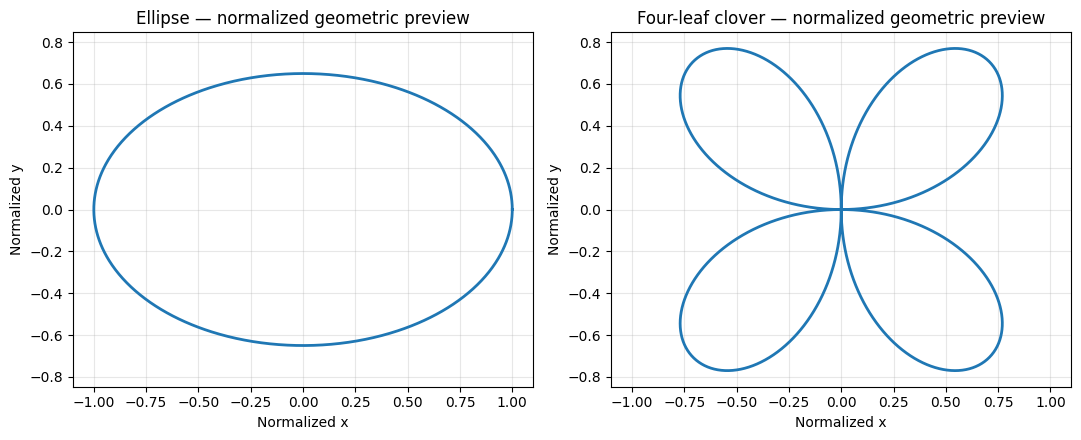

In [9]:
phase=np.linspace(0,2*np.pi,1200)
fig,axs=plt.subplots(1,2,figsize=(11,4.5))
axs[0].plot(np.cos(phase),.65*np.sin(phase),lw=2)
axs[0].set_title('Ellipse — normalized geometric preview')
axs[1].plot(.5*(np.sin(3*phase)+np.sin(phase)),
            .5*(np.cos(phase)-np.cos(3*phase)),lw=2)
axs[1].set_title('Four-leaf clover — normalized geometric preview')
for ax in axs:
    ax.set(xlabel='Normalized x',ylabel='Normalized y')
    ax.axis('equal');ax.grid(alpha=.3)
plt.tight_layout();plt.show()

### Trajectory simulation

The reference trajectories are converted into motor voltages using the inverse model. The plots compare the prescribed paths with the integrated motion and show the required input signals.

### Q1.4 — Simulation parameters

For the numerical example, the pulley radius is 9.5 mm, the moving mass is 85 g, the ellipse semi-axes are 45 and 30 mm, and the angular frequency is 0.8 rad/s. These are assumed values rather than measured printer data. The input is calculated by inverse dynamics with matched initial conditions; the resulting tracking error therefore describes the ideal feedforward model.

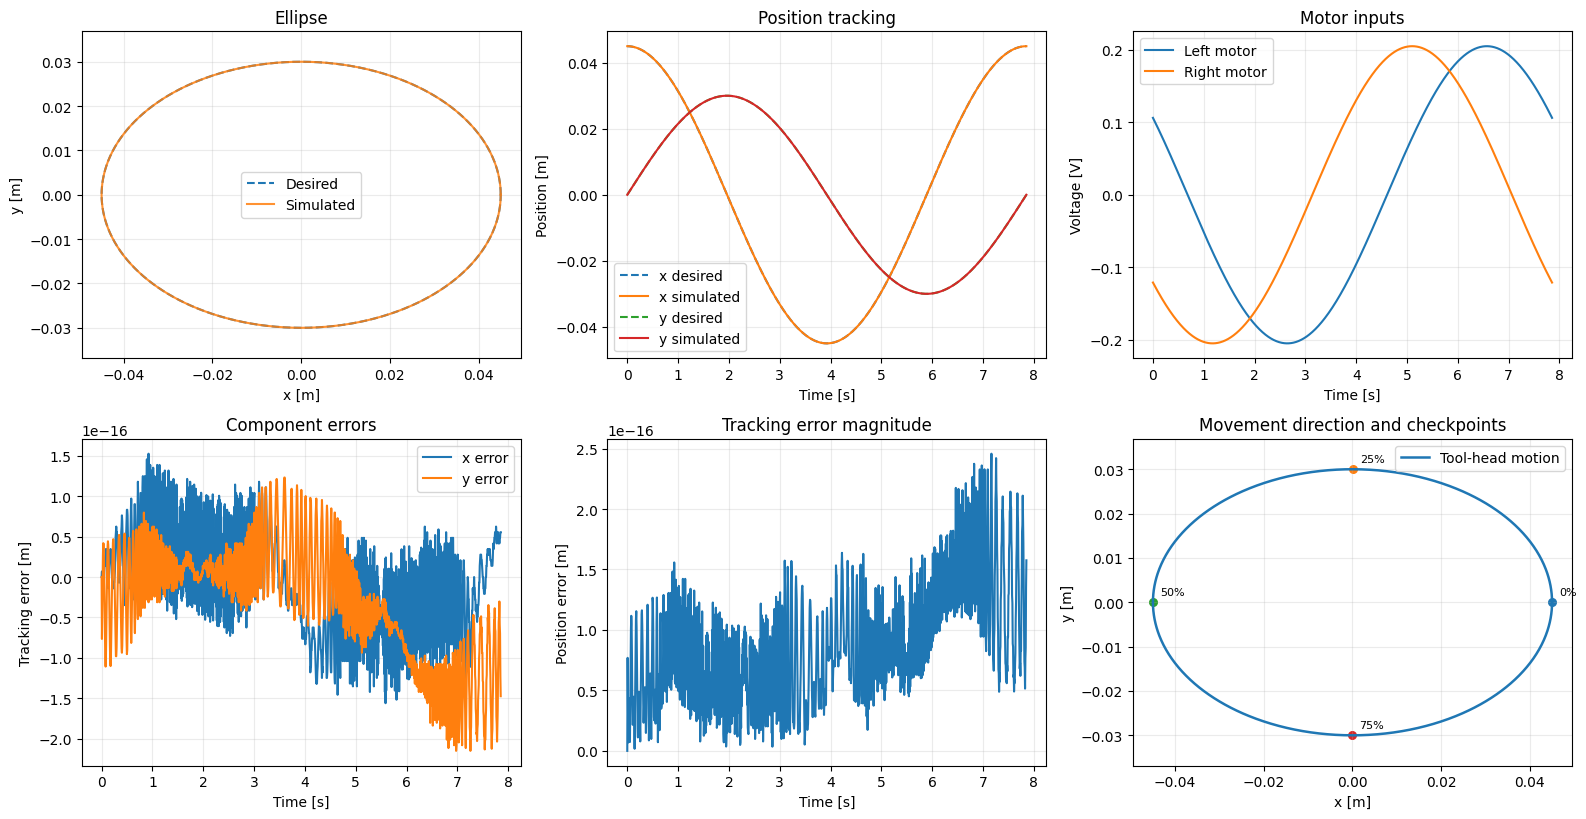

Maximum XY position error [m]: 2.4574364858260787e-16
XY RMSE [m]: 9.945191448373328e-17
Peak absolute motor voltage [V]: 0.20513664457500247


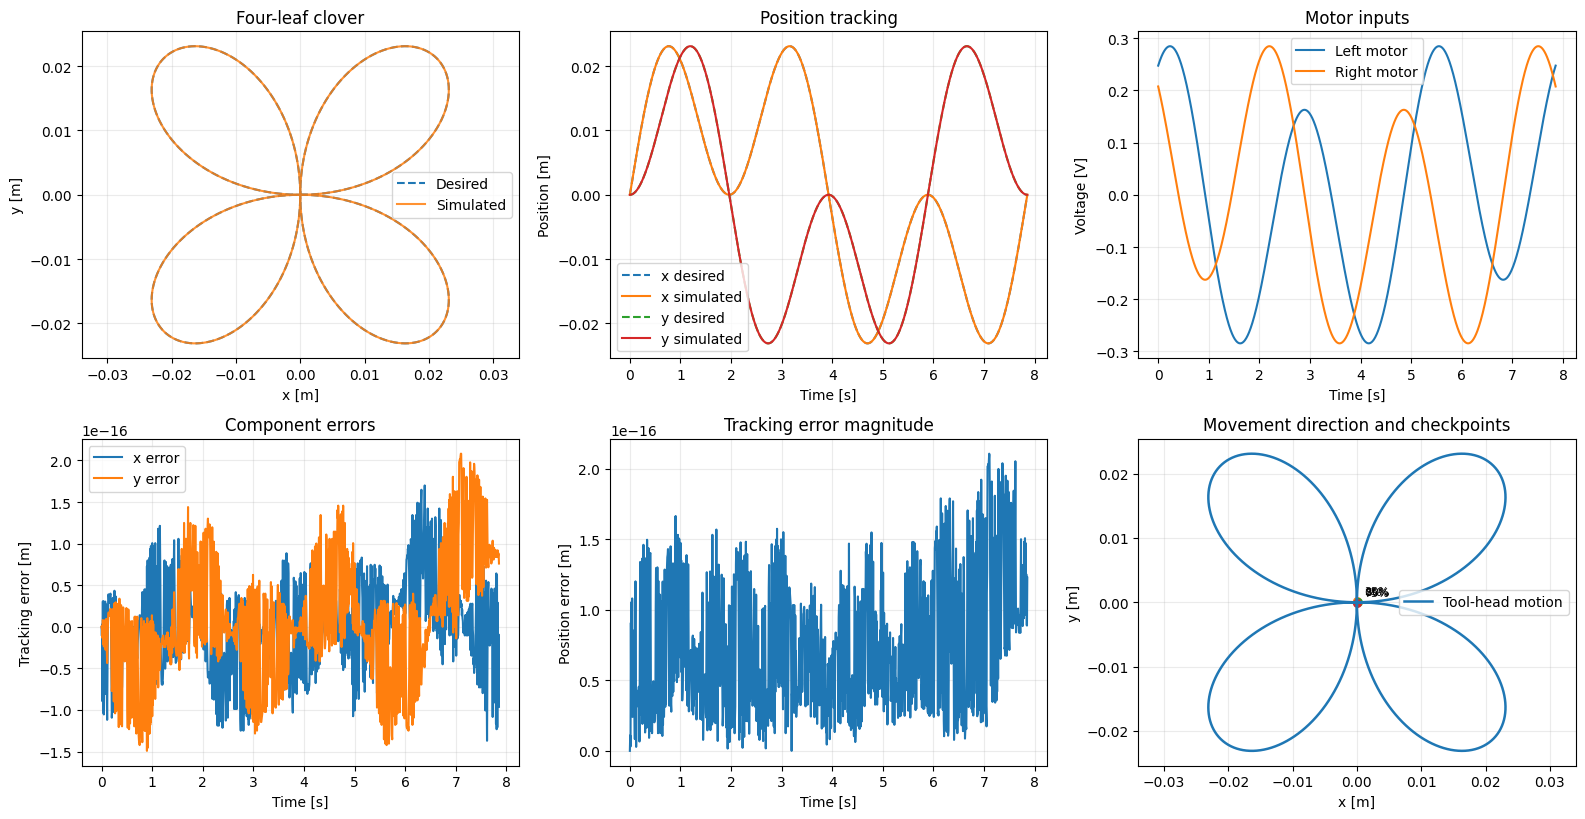

Maximum XY position error [m]: 2.1049566689853461e-16
XY RMSE [m]: 8.549526163555171e-17
Peak absolute motor voltage [V]: 0.2844951502107299


In [10]:
# Assumed motor and trajectory parameters.
# SI units: kg, m, s, H, ohm, N*m/A (= V*s/rad).
physical = dict(r_m=0.0095, J_m=1.6e-5, m=0.085, L_m=0.006, R_m=5.6, K_m=0.045)
geometry = dict(x_c=0.0, y_c=0.0, A_e=0.045, B_e=0.030, C=0.030, omega=0.8)

def all_supplied(*dicts):
    return all(v is not None for d in dicts for v in d.values())

def numerical_trajectory(name, physical, geometry, points=1200):
    if not all_supplied(physical, geometry):
        raise ValueError('Supply every physical and geometry parameter first.')
    if any(physical[k] <= 0 for k in physical) or geometry['omega'] <= 0:
        raise ValueError('Physical parameters and omega must be positive.')
    substitutions = {
        rm:physical['r_m'], Jm:physical['J_m'], m:physical['m'],
        Lm:physical['L_m'], Rm:physical['R_m'], Km:physical['K_m'],
        xc:geometry['x_c'], yc:geometry['y_c'],
        Ae:geometry['A_e'], Be:geometry['B_e'], C:geometry['C'], w:geometry['omega']
    }
    entry = reference[name]
    def compile_vec(expr):
        expr = sp.Matrix(expr).subs(substitutions)
        fun = sp.lambdify(t, expr, modules='numpy', cse=True)
        return lambda times: np.asarray(fun(float(times)), dtype=float).reshape(-1)
    d = [compile_vec(z) for z in entry['derivatives']]
    u = compile_vec(entry['voltage_xy'])
    motor_u = compile_vec(entry['voltage_motors'])
    T = 2*np.pi/geometry['omega']
    ts = np.linspace(0,T,points)
    jeq = physical['J_m'] + physical['m']*physical['r_m']**2/2
    g = physical['r_m']*physical['K_m']/(2*jeq)
    initial = np.r_[d[0](0), d[1](0), d[2](0)/g]  # [x,y,xdot,ydot,ix,iy]
    def ode(time, state):
        x,y,vx,vy,ix_,iy_ = state
        ux_,uy_ = u(time)
        return [vx,vy,g*ix_,g*iy_,
                (ux_-physical['R_m']*ix_-2*physical['K_m']*vx/physical['r_m'])/physical['L_m'],
                (uy_-physical['R_m']*iy_-2*physical['K_m']*vy/physical['r_m'])/physical['L_m']]
    sol = solve_ivp(ode, (0,T), initial, t_eval=ts, rtol=1e-9, atol=1e-11)
    if not sol.success: raise RuntimeError(sol.message)
    desired = np.array([d[0](ti) for ti in ts]).T
    voltages = np.array([motor_u(ti) for ti in ts]).T
    fig,ax = plt.subplots(2,3,figsize=(16,8.3))
    ax=ax.ravel()
    ax[0].plot(desired[0],desired[1],'--',label='Desired')
    ax[0].plot(sol.y[0],sol.y[1],label='Simulated',alpha=.85)
    ax[0].axis('equal'); ax[0].set(xlabel='x [m]',ylabel='y [m]',title=name)
    ax[0].legend()
    ax[1].plot(ts,desired[0],'--',label='x desired')
    ax[1].plot(ts,sol.y[0],label='x simulated')
    ax[1].plot(ts,desired[1],'--',label='y desired')
    ax[1].plot(ts,sol.y[1],label='y simulated')
    ax[1].set(xlabel='Time [s]',ylabel='Position [m]',title='Position tracking'); ax[1].legend()
    ax[2].plot(ts,voltages[0],label='Left motor')
    ax[2].plot(ts,voltages[1],label='Right motor')
    ax[2].set(xlabel='Time [s]',ylabel='Voltage [V]',title='Motor inputs'); ax[2].legend()
    errors = np.hypot(sol.y[0]-desired[0],sol.y[1]-desired[1])
    ax[3].plot(ts,sol.y[0]-desired[0],label='x error')
    ax[3].plot(ts,sol.y[1]-desired[1],label='y error')
    ax[3].set(xlabel='Time [s]',ylabel='Tracking error [m]',title='Component errors');ax[3].legend();ax[3].grid(alpha=.3)
    ax[4].plot(ts,errors,label='Euclidean XY error')
    ax[4].set(xlabel='Time [s]',ylabel='Position error [m]',title='Tracking error magnitude');ax[4].grid(alpha=.3)
    ax[5].plot(sol.y[0],sol.y[1],lw=1.8,label='Tool-head motion')
    for frac in [0,.25,.5,.75]:
        idx=int(frac*(len(ts)-1))
        ax[5].scatter(sol.y[0,idx],sol.y[1,idx],s=30)
        ax[5].annotate(f'{frac:.0%}',(sol.y[0,idx],sol.y[1,idx]),xytext=(5,5),textcoords='offset points',fontsize=8)
    ax[5].set(xlabel='x [m]',ylabel='y [m]',title='Movement direction and checkpoints');ax[5].axis('equal');ax[5].legend()
    for axt in ax: axt.grid(alpha=.25)
    fig.tight_layout(); plt.show()
    print('Maximum XY position error [m]:', np.max(errors))
    print('XY RMSE [m]:', np.sqrt(np.mean(errors**2)))
    print('Peak absolute motor voltage [V]:', np.max(np.abs(voltages)))
    return sol

if all_supplied(physical, geometry):
    ellipse_result = numerical_trajectory('Ellipse',physical,geometry)
    clover_result = numerical_trajectory('Four-leaf clover',physical,geometry)
else:
    print('Q1.4 simulation not run: numerical parameters have not been supplied.')

---
# Q1.5 — Nozzle electrical and thermal dynamics

The electrical circuit consists of an inductor $L_n$ in series with a parallel combination of heater resistance $R_n$ and capacitor $C_n$. Let $i_n$ be the inductor current and $v_n$ the voltage across the parallel branch.

**Electrical equations** (KVL and KCL):

$$u_n=L_n\dot i_n+v_n,\qquad i_n=C_n\dot v_n+\frac{v_n}{R_n}.$$

Hence

$$\boxed{\dot i_n=\frac{u_n-v_n}{L_n}},\qquad
\boxed{\dot v_n=\frac{i_n-v_n/R_n}{C_n}}.$$

The heater dissipates $P_n=v_n^2/R_n$. We lump heat exchange with the environment and filament into one thermal resistance $R_{t,n}$ relative to $T_e$:

$$C_{t,n}\dot T_n=\underbrace{\frac{v_n^2}{R_n}}_{\text{Joule heating}}
-\underbrace{\frac{T_n-T_e}{R_{t,n}}}_{\text{heat loss}}.$$

Thus, with $\mathbf x_n=[T_n,i_n,v_n]^T$ and input $u_n$,

$$\boxed{\dot{\mathbf x}_n=
\begin{bmatrix}
\dfrac{v_n^2/R_n-(T_n-T_e)/R_{t,n}}{C_{t,n}}\\[8pt]
\dfrac{u_n-v_n}{L_n}\\[8pt]
\dfrac{i_n-v_n/R_n}{C_n}
\end{bmatrix}}.$$

The model is nonlinear because heating depends on $v_n^2$.

For constant voltage, the equilibrium is

$$\boxed{v_n^*=u_n^*,\quad i_n^*=u_n^*/R_n,\quad
T_n^*=T_e+\frac{R_{t,n}}{R_n}(u_n^*)^2}.$$

A positive equilibrium voltage for a target $T_{\rm ref}\ge T_e$ is

$$u_n^*=\sqrt{\frac{R_n}{R_{t,n}}(T_{\rm ref}-T_e)}.$$


The combined thermal resistance is an approximation: the filament and the surrounding air are not modelled as separate thermal states.


In [11]:
Ln, Cn, Rn, Ctn, Rtn, Te = sp.symbols(
    'L_n C_n R_n C_tn R_tn T_e', positive=True)
Tn, in_, vn, un = sp.symbols('T_n i_n v_n u_n', real=True)
fn = sp.Matrix([
    (vn**2/Rn-(Tn-Te)/Rtn)/Ctn,
    (un-vn)/Ln,
    (in_-vn/Rn)/Cn
])
print('Nonlinear nozzle state equations:'); sp.pprint(fn)
steady = {vn:un, in_:un/Rn, Tn:Te+Rtn*un**2/Rn}
assert sp.simplify(fn.subs(steady)) == sp.zeros(3,1)
print('Equilibrium verified symbolically.')

Nonlinear nozzle state equations:
⎡               2⎤
⎢  -Tₑ + Tₙ   vₙ ⎥
⎢- ──────── + ───⎥
⎢    Rₜₙ      Rₙ ⎥
⎢────────────────⎥
⎢      Cₜₙ       ⎥
⎢                ⎥
⎢    uₙ - vₙ     ⎥
⎢    ───────     ⎥
⎢      Lₙ        ⎥
⎢                ⎥
⎢         vₙ     ⎥
⎢    iₙ - ──     ⎥
⎢         Rₙ     ⎥
⎢    ───────     ⎥
⎣      Cₙ        ⎦
Equilibrium verified symbolically.


---
# Q1.6 — Printing and cooling an elliptical filament (PDE)

We model the first deposited filament layer along the ellipse. Let $s$ denote **arc length along the deposited filament**, not the Cartesian $x$ coordinate. The temperature $T(s,t)$ is averaged across a square cross section of side $a_f$.

The cross-sectional area is $A_f=a_f^2$. Per unit filament length, **three faces** contact the air (exposed perimeter $3a_f$) and **one face** contacts the heated print bed (contact perimeter $a_f$).

Consider a segment $ds$. Its stored-energy rate is $\rho c_p A_f ds\,\partial T/\partial t$. Fourier conduction along the filament contributes $kA_f ds\,\partial^2T/\partial s^2$. Heat exchange with air and bed contributes $-3h_e a_f ds(T-T_e)$ and $+h_b a_f ds(T_b-T)$, respectively.

The energy balance yields

$$\rho c_p a_f^2\frac{\partial T}{\partial t}
=k a_f^2\frac{\partial^2T}{\partial s^2}
-3h_ea_f(T-T_e)+h_ba_f(T_b-T).$$

Define

$$\alpha=\frac{k}{\rho c_p},\quad
\beta_e=\frac{3h_e}{\rho c_p a_f},\quad
\beta_b=\frac{h_b}{\rho c_p a_f}.$$

Then the **governing PDE** is

$$\boxed{\frac{\partial T}{\partial t}
=\alpha\frac{\partial^2T}{\partial s^2}
-\beta_e(T-T_e)+\beta_b(T_b-T)}.$$

## Growing spatial domain

For the elliptical print path

$$x(t)=x_c+A_e\cos(\omega t),\quad y(t)=y_c+B_e\sin(\omega t),$$

the deposition speed and deposited length are

$$v_p(t)=\omega\sqrt{A_e^2\sin^2(\omega t)+B_e^2\cos^2(\omega t)},\quad
\boxed{L(t)=\int_0^t v_p(\tau)\,d\tau}.$$

The printing interval is $0<t<t_p=2\pi/\omega$ and the physical domain is $0<s<L(t)$. Newly deposited material enters at $T_{\rm dep}(t)$, approximated by nozzle temperature $T_n(t)$ if available. During printing, the first end is insulated and the growing end receives new material at deposition temperature:

$$\partial_sT(0,t)=0,\qquad T(L(t),t)=T_{\rm dep}(t).$$

After the path closes, the ring has fixed length $L_f=L(t_p)$ and periodic conditions:

$$T(0,t)=T(L_f,t),\qquad \partial_sT(0,t)=\partial_sT(L_f,t).$$

At closure, the existing temperature profile is preserved (no reset). A perfect thermal joint is assumed. The thermal equilibrium is

$$\boxed{T_\infty=\frac{3h_eT_e+h_bT_b}{3h_e+h_b}}.$$

**Cooling criterion:** After printing, stop when $\max_sT-\min_sT\le\varepsilon_T$. This measures near-uniformity, not necessarily a safe temperature for the next layer.

## Numerical approach

Use a finite-volume/finite-difference **growing-cell approximation**: deposit equal-length filament cells at their calculated arc-length arrival times, integrate the existing cells between depositions, and connect the two ends periodically after the final cell is deposited. The discretization is a staircase approximation to the continuously growing domain; convergence should be checked by increasing $N$. No filament cells exist before they are deposited.

For interior cells of uniform width $\Delta s$,

$$\boxed{\dot T_i=\alpha\frac{T_{i+1}-2T_i+T_{i-1}}{\Delta s^2}
-\beta_e(T_i-T_e)+\beta_b(T_b-T_i)}.$$

Insulated open ends use a zero inter-cell heat flux; periodic cells wrap around the closed ring.

The numerical example uses approximate PLA material properties, a 0.65 mm square filament cross section, a 345 K bed, 295 K ambient air, and a deposition temperature of 465 K. The heat-transfer coefficients are assumed, so the results are not calibrated to a specific printer.


Print time [s]: 7.85398; total length [m]: 0.237982
Thermal equilibrium [K]: 327.178
Cooling time after print [s]: 56.6954


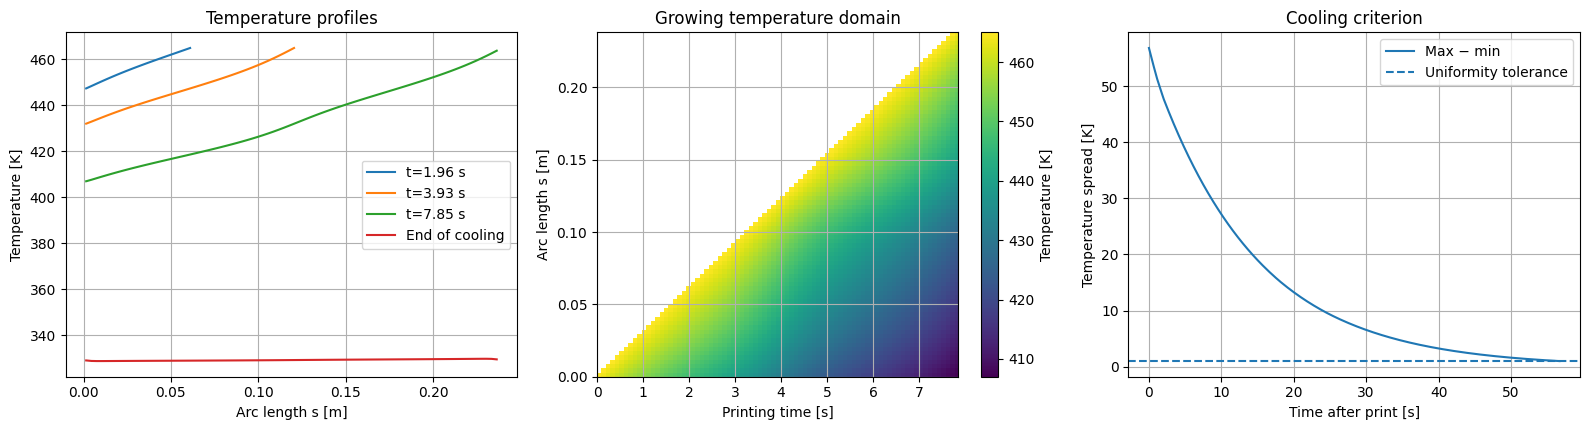

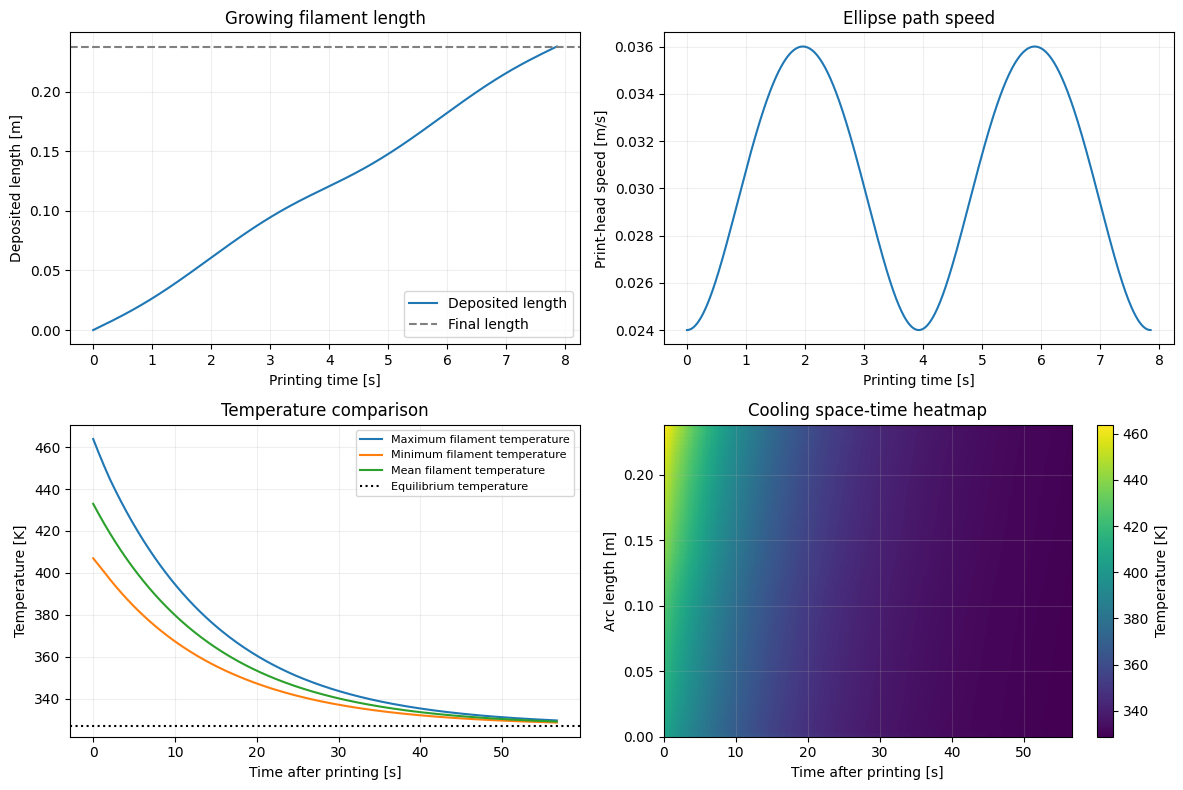


Cooling temperature summary:
t_after_print=0 s | min=407.01 K | mean=432.94 K | max=463.82 K | spread=56.81 K
t_after_print=28.462 s | min=338.39 K | mean=341.76 K | max=345.68 K | spread=7.2983 K
t_after_print=56.695 s | min=328.76 K | mean=329.22 K | max=329.76 K | spread=1 K


In [14]:
# Approximate PLA properties and assumed printing conditions.
# Constant properties and lumped surface heat-transfer coefficients are assumed.
filament_parameters = dict(a_f=0.00065, k=0.20, rho=1240.0, c_p=1800.0,
                           h_e=12.0, h_b=65.0, T_e=295.0, T_b=345.0)
filament_setup = dict(A_e=0.045, B_e=0.030, omega=0.8, T_deposition=465.0,
                      epsilon_T=1.0, N_cells=80, max_cooling_time=250.0)

def ellipse_deposition_schedule(Ae_,Be_,omega,N,quadrature_points=12001):
    """Return deposition times for N equal arc-length cells."""
    t_print=2*np.pi/omega
    grid=np.linspace(0,t_print,quadrature_points)
    speed=omega*np.sqrt(Ae_**2*np.sin(omega*grid)**2 +
                        Be_**2*np.cos(omega*grid)**2)
    length=cumulative_trapezoid(speed,grid,initial=0)
    total=length[-1]
    ends=np.linspace(0,total,N+1)
    deposition_times=np.interp(ends, length, grid)
    return deposition_times,total,t_print

def simulate_filament(params,setup):
    if not all_supplied(params,setup):
        raise ValueError('All filament and print settings must be provided.')
    if any(params[k] <= 0 for k in ['a_f','k','rho','c_p','h_e','h_b']):
        raise ValueError('Material and heat-transfer coefficients must be positive.')
    N=int(setup['N_cells'])
    if N<3 or N != setup['N_cells']: raise ValueError('N_cells must be an integer >= 3.')
    dep_times,Lf,tp=ellipse_deposition_schedule(setup['A_e'],setup['B_e'],
                                                 setup['omega'],N)
    ds=Lf/N
    alpha=params['k']/(params['rho']*params['c_p'])
    be=3*params['h_e']/(params['rho']*params['c_p']*params['a_f'])
    bb=params['h_b']/(params['rho']*params['c_p']*params['a_f'])
    Tinf=(be*params['T_e']+bb*params['T_b'])/(be+bb)
    dep=setup['T_deposition']
    def Tdeposit(time):
        return float(dep(time) if callable(dep) else dep)
    def ode(_,temp,closed):
        # Conservative fluxes between cell centres. For the open strip,
        # the exterior end faces have zero conductive flux.
        right=np.zeros_like(temp)
        left=np.zeros_like(temp)
        if len(temp)>1:
            flux=alpha*(temp[1:]-temp[:-1])/ds**2
            right[:-1]=flux
            left[1:]=-flux
        if closed:
            wrap=alpha*(temp[0]-temp[-1])/ds**2
            right[-1]=wrap
            left[0]=-wrap
        return right+left-be*(temp-params['T_e'])+bb*(params['T_b']-temp)
    # Each interval is integrated with its current number of cells.
    # At a deposition event a new cell is appended at the deposition temperature.
    snapshots=[]
    temp=np.array([Tdeposit(0.0)])
    snapshots.append((0.0,temp.copy()))
    for j in range(1,N):
        start=dep_times[j-1]
        stop=dep_times[j]
        if stop>start:
            sol=solve_ivp(lambda tt,yy:ode(tt,yy,False),(start,stop),temp,
                          method='BDF',rtol=1e-6,atol=1e-8)
            if not sol.success: raise RuntimeError(sol.message)
            temp=sol.y[:,-1]
        temp=np.r_[temp,Tdeposit(stop)]
        snapshots.append((stop,temp.copy()))
    # The final cell has just been deposited; evolve to the exact closure time.
    if tp>dep_times[N-1]:
        sol=solve_ivp(lambda tt,yy:ode(tt,yy,False),
                      (dep_times[N-1],tp),temp,method='BDF',rtol=1e-6,atol=1e-8)
        if not sol.success: raise RuntimeError(sol.message)
        temp=sol.y[:,-1]
    snapshots.append((tp,temp.copy()))
    tol=setup['epsilon_T']
    maxcool=setup['max_cooling_time']
    def uniform_event(time,values):
        return np.max(values)-np.min(values)-tol
    uniform_event.terminal=True
    uniform_event.direction=-1
    if np.ptp(temp)<=tol:
        tcool=0.0
        cooling_times=np.array([tp]); cooling_profiles=temp[:,None]
    else:
        # Dense output supports accurate plotting even when a terminal event fires.
        sol=solve_ivp(lambda tt,yy:ode(tt,yy,True),(tp,tp+maxcool),temp,
                      method='BDF',events=uniform_event,dense_output=True,
                      rtol=1e-7,atol=1e-9)
        if not sol.success: raise RuntimeError(sol.message)
        final=sol.t[-1]
        cooling_times=np.linspace(tp,final,250)
        cooling_profiles=sol.sol(cooling_times)
        tcool=float(sol.t_events[0][0]-tp) if len(sol.t_events[0]) else None
    print(f'Print time [s]: {tp:.6g}; total length [m]: {Lf:.6g}')
    print(f'Thermal equilibrium [K]: {Tinf:.6g}')
    if tcool is None:
        print('Near-uniform temperature not reached within the cooling horizon.')
    else:
        print(f'Cooling time after print [s]: {tcool:.6g}')
    # Snapshot plot: early/middle/end-of-print and end-of-cooling.
    fig,axs=plt.subplots(1,3,figsize=(16,4.4))
    for idx in sorted(set([max(0,N//4),max(0,N//2),N])):
        ti,vals=snapshots[idx]
        positions=(np.arange(len(vals))+.5)*ds
        axs[0].plot(positions,vals,label=f't={ti:.3g} s')
    axs[0].plot((np.arange(N)+.5)*ds,cooling_profiles[:,-1],
                label='End of cooling')
    axs[0].set(xlabel='Arc length s [m]',ylabel='Temperature [K]',
               title='Temperature profiles');axs[0].legend()
    # Heatmap: cells not yet deposited are NaN (no artificial temperature).
    matrix=np.full((N,len(snapshots)),np.nan)
    for j,(_,vals) in enumerate(snapshots): matrix[:len(vals),j]=vals
    image=axs[1].imshow(matrix,origin='lower',aspect='auto',interpolation='nearest',
                         extent=[0,tp,0,Lf])
    axs[1].set(xlabel='Printing time [s]',ylabel='Arc length s [m]',
               title='Growing temperature domain')
    fig.colorbar(image,ax=axs[1],label='Temperature [K]')
    gap=np.max(cooling_profiles,axis=0)-np.min(cooling_profiles,axis=0)
    axs[2].plot(cooling_times-tp,gap,label='Max − min')
    axs[2].axhline(tol,linestyle='--',label='Uniformity tolerance')
    axs[2].set(xlabel='Time after print [s]',ylabel='Temperature spread [K]',
               title='Cooling criterion');axs[2].legend()
    fig.tight_layout();plt.show()
    # Arc length is determined by the ellipse's instantaneous speed.
    dense_t=np.linspace(0,tp,1000)
    dense_speed=setup['omega']*np.sqrt(setup['A_e']**2*np.sin(setup['omega']*dense_t)**2+
                                       setup['B_e']**2*np.cos(setup['omega']*dense_t)**2)
    dense_L=cumulative_trapezoid(dense_speed,dense_t,initial=0)
    fig,axs2=plt.subplots(2,2,figsize=(12,8))
    axs2[0,0].plot(dense_t,dense_L,label='Deposited length')
    axs2[0,0].axhline(Lf,linestyle='--',color='gray',label='Final length')
    axs2[0,0].set(xlabel='Printing time [s]',ylabel='Deposited length [m]',title='Growing filament length');axs2[0,0].legend()
    axs2[0,1].plot(dense_t,dense_speed)
    axs2[0,1].set(xlabel='Printing time [s]',ylabel='Print-head speed [m/s]',title='Ellipse path speed')
    t_rel=cooling_times-tp
    axs2[1,0].plot(t_rel,np.max(cooling_profiles,axis=0),label='Maximum filament temperature')
    axs2[1,0].plot(t_rel,np.min(cooling_profiles,axis=0),label='Minimum filament temperature')
    axs2[1,0].plot(t_rel,np.mean(cooling_profiles,axis=0),label='Mean filament temperature')
    axs2[1,0].axhline(Tinf,ls=':',color='black',label='Equilibrium temperature')
    axs2[1,0].set(xlabel='Time after printing [s]',ylabel='Temperature [K]',title='Temperature comparison');axs2[1,0].legend(fontsize=8)
    # A space-time temperature heatmap including the cooling phase.
    img=axs2[1,1].imshow(cooling_profiles,origin='lower',aspect='auto',interpolation='nearest',
                         extent=[t_rel[0],t_rel[-1] if len(t_rel)>1 else 1,0,Lf])
    axs2[1,1].set(xlabel='Time after printing [s]',ylabel='Arc length [m]',title='Cooling space-time heatmap')
    fig.colorbar(img,ax=axs2[1,1],label='Temperature [K]')
    for axt in axs2.ravel(): axt.grid(alpha=.2)
    fig.tight_layout();plt.show()
    # Thermal profile summary for the report (no invented measurements).
    print('\nCooling temperature summary:')
    for idx in sorted(set([0,len(t_rel)//2,len(t_rel)-1])):
        vals=cooling_profiles[:,idx]
        print(f't_after_print={t_rel[idx]:.5g} s | min={np.min(vals):.5g} K | '
              f'mean={np.mean(vals):.5g} K | max={np.max(vals):.5g} K | spread={np.ptp(vals):.5g} K')
    return dict(print_time=tp,filament_length=Lf,cooling_time=tcool,
                equilibrium_temperature=Tinf,snapshots=snapshots,
                cooling_times=cooling_times,cooling_profiles=cooling_profiles)

if all_supplied(filament_parameters,filament_setup):
    filament_result=simulate_filament(filament_parameters,filament_setup)
else:
    print('Q1.6 simulation not run: numerical parameters have not been supplied.')

---
## Part 2 — Finite-state models

The first machine handles filament replacement. The second reads motion commands and motor-rotation measurements to detect when the print head reaches the home corner.

In [ ]:
import os
import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
from scipy.integrate import solve_ivp
from dataclasses import dataclass
from IPython.display import display, Markdown, Image
from html import escape as html_escape

plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.grid': True,
                     'grid.alpha': 0.20, 'font.size': 10, 'savefig.dpi': 150})

# Use Graphviz if its executable is available. Otherwise render directly with
def locate_graphviz():
    exe = shutil.which('dot')
    if exe:
        return exe
    candidates = [Path(sys.prefix) / 'Library' / 'bin',
                  Path(sys.prefix) / 'Scripts',
                  Path(r'C:\Program Files\Graphviz\bin'),
                  Path(r'C:\Program Files (x86)\Graphviz\bin')]
    for folder in candidates:
        if (folder / 'dot.exe').is_file():
            os.environ['PATH'] = str(folder) + os.pathsep + os.environ.get('PATH', '')
            return str(folder / 'dot.exe')
    return None

DOT_EXE = locate_graphviz()
try:
    from graphviz import Digraph
except ImportError:
    Digraph = None

# Matplotlib fallback. States are circles; Moore states are divided by a
# horizontal rule. Hybrid states contain flow and invariant, with guards/resets
# on the arrows. This works even if Graphviz is not installed on Windows.
def _fallback_diagram(nodes, edges, title, accept=(), initial=None,
                      rankdir='TB', moore=False, hybrid=False):
    keys = list(nodes)
    N = len(keys)
    if N == 9 and not hybrid and not moore:
        xy = {k: (j % 3 * 5.0, -(j // 3) * 4.4) for j,k in enumerate(keys)}
        radius = 1.05
    elif hybrid and rankdir == 'LR':
        if N > 5:
            # Four modes per row, with the return path along the lower row.
            xy = {k: ((j if j < 4 else 7-j) * 8.5,
                       0 if j < 4 else -8.0) for j,k in enumerate(keys)}
        else:
            xy = {k: ((j if j < 3 else 4-j) * 8.5,
                       0 if j < 3 else -8.0) for j,k in enumerate(keys)}
        radius = 2.15
    elif hybrid:
        cols = 2 if N > 5 else 1
        xy = {k: ((j % cols) * 11.5, -(j // cols) * 7.0) for j,k in enumerate(keys)}
        radius = 2.35 if N > 5 else 2.15
    else:
        cols = 2 if N > 5 else 1
        xy = {k: ((j % cols) * 6.8, -(j // cols) * 4.6) for j,k in enumerate(keys)}
        radius = 1.55
    fig,ax=plt.subplots(figsize=((19, 8) if hybrid and rankdir=='LR' else (17, 16 if N>5 else 12)),layout='constrained')
    ax.set_aspect('equal');ax.axis('off')
    for k,(x,y) in xy.items():
        fill = '#dcfce7' if k in accept else ('#eff6ff' if moore else '#f8fafc')
        ax.add_patch(Circle((x,y),radius,facecolor=fill,edgecolor='#334155',lw=1.6,zorder=3))
        if k in accept:
            ax.add_patch(Circle((x,y),radius-.12,facecolor='none',edgecolor='#334155',lw=1.2,zorder=3))
        label=nodes[k]
        if moore:
            top,bottom=label.split('\n',1)
            ax.plot([x-radius*.88,x+radius*.88],[y,y],color='#334155',lw=1.1,zorder=4)
            ax.text(x,y+radius*.47,top,ha='center',va='center',fontsize=9,weight='bold',zorder=5)
            ax.text(x,y-radius*.43,bottom,ha='center',va='center',fontsize=7.0,zorder=5,linespacing=1.15)
        else:
            ax.text(x,y,label,ha='center',va='center',fontsize=7 if hybrid else 9,zorder=5,linespacing=1.35)
    # Straight arrows are kept outside the circles, with short guard labels.
    for idx,(s,d,lab) in enumerate(edges):
        x1,y1=xy[s];x2,y2=xy[d]
        if s==d:
            ax.annotate('',xy=(x1+radius*.8,y1+radius*.8),xytext=(x1+radius*.55,y1+radius*1.25),
                        arrowprops=dict(arrowstyle='->',color='#64748b',lw=1.0,connectionstyle='arc3,rad=.8'))
            ax.text(x1+radius*1.25,y1+radius*1.28,lab,fontsize=6,ha='left',va='center')
            continue
        dx=x2-x1;dy=y2-y1;L=np.hypot(dx,dy);ux,uy=dx/L,dy/L
        start=(x1+ux*radius,y1+uy*radius);end=(x2-ux*radius,y2-uy*radius)
        ax.add_patch(FancyArrowPatch(start,end,arrowstyle='-|>',mutation_scale=10,lw=1.0,
                                      color='#64748b',zorder=1))
        mx=(start[0]+end[0])/2;my=(start[1]+end[1])/2
        # Use white labels to prevent arrows from crossing text.
        ax.text(mx,my,lab,fontsize=6.0,ha='center',va='center',zorder=2,
                bbox=dict(facecolor='white',edgecolor='none',pad=1.5))
    if initial in xy:
        x,y=xy[initial]
        ax.annotate('',xy=(x-radius,y),xytext=(x-radius-1.0,y),
                    arrowprops=dict(arrowstyle='-|>',color='black',lw=1.3))
    ax.set_xlim(min(x for x,y in xy.values())-radius-3,max(x for x,y in xy.values())+radius+3)
    ax.set_ylim(min(y for x,y in xy.values())-radius-3,max(y for x,y in xy.values())+radius+3)
    ax.set_title(title,fontsize=14,pad=15)
    plt.show()

def diagram(nodes, edges, title, accept=(), initial=None,
            rankdir='TB', moore=False, hybrid=False):
    """Lecture notation: Moore split circles; circular DFA/hybrid states."""
    if Digraph is None or DOT_EXE is None:
        return _fallback_diagram(nodes,edges,title,accept,initial,rankdir,moore,hybrid)
    g=Digraph(comment=title,format='png',graph_attr={
        'rankdir':rankdir,'splines':'polyline','nodesep':'0.55','ranksep':'1.05',
        'pad':'0.65','dpi':'170','label':title,'labelloc':'t','fontsize':'17',
        'fontname':'Arial','overlap':'false','outputorder':'edgesfirst'})
    g.attr('node',shape='circle',style='filled',fillcolor='#f1f5f9',
           color='#334155',fontname='Arial',fontsize='10',margin='0.16')
    for key,label in nodes.items():
        if moore:
            top,bottom=label.split('\n',1)
            # Graphviz HTML-like labels support <HR/> between table rows.
            html=('<TABLE BORDER="0" CELLBORDER="0" CELLSPACING="0" CELLPADDING="7">'
                  '<TR><TD><B>'+html_escape(top)+'</B></TD></TR><HR/>'
                  '<TR><TD>'+html_escape(bottom).replace('\n','<BR/>')+'</TD></TR></TABLE>')
            g.node(key,label='<'+html+'>',shape='circle',fillcolor='#eff6ff')
        else:
            g.node(key,label=label,shape='doublecircle' if key in accept else 'circle',
                   fillcolor='#dcfce7' if key in accept else '#f1f5f9')
    g.attr('edge',fontname='Arial',fontsize='8',color='#475569',arrowsize='.75')
    for s,d,lab in edges:
        g.edge(s,d,label=lab)
    if initial is not None:
        g.node('START',label='',shape='point',width='.09',fillcolor='black')
        g.edge('START',initial)
    try:
        display(Image(g.pipe(format='png')))
    except Exception as exc:
        print('Graphviz rendering unavailable; using Matplotlib:',str(exc)[:100])
        _fallback_diagram(nodes,edges,title,accept,initial,rankdir,moore,hybrid)

def plot_transition_lines(ax,events):
    for ev in events:
        ax.axvline(ev[0],color='0.55',lw=.65,ls=':',alpha=.65)

print('Diagram renderer:', 'Graphviz' if DOT_EXE and Digraph else 'Matplotlib (no Graphviz required)')

Diagram renderer: Graphviz


# 2.1 Filament Replacement — Moore Machine

A filament replacement is initiated by either a colour-change request $C$ or an empty-spool signal $F$. The sequence stops the print, moves to the wipe tower at $(0,0)$, cleans the nozzle, cools it, loads new filament, reheats, returns to the stored print position, and resumes printing.

The controller is represented by a Moore machine

$$\mathcal M=(Q,\Sigma,\Gamma,\delta,\lambda,q_0),\qquad\lambda:Q\to\Gamma.$$

Here $\lambda$ assigns an action to each **state**, while $\delta$ determines transitions from completion events. The state label occupies the upper half of each circle and the associated output occupies the lower half. The print-progress clock is paused throughout the replacement operation.

The state sequence is

$$\mathrm{PRINT}\xrightarrow{C\lor F}\mathrm{STOP}\xrightarrow{\mathrm{stopped}}\mathrm{MOVE}\xrightarrow{\mathrm{at\ tower}}\mathrm{WIPE}\xrightarrow{\mathrm{wipe\ done}}\mathrm{COOL}\xrightarrow{T_n\le T_{low}}\mathrm{LOAD}\xrightarrow{\mathrm{loaded}}\mathrm{HEAT}\xrightarrow{T_n\ge T_{high}}\mathrm{RETURN}\xrightarrow{\mathrm{returned}}\mathrm{PRINT}.$$

The return state restores the saved position before printing restarts. This separates the return motion from `PRINT`, since the print-progress clock must remain stopped until the return is complete. Temperature thresholds are treated as conditions here; their continuous evolution is modelled in Section 3.1.


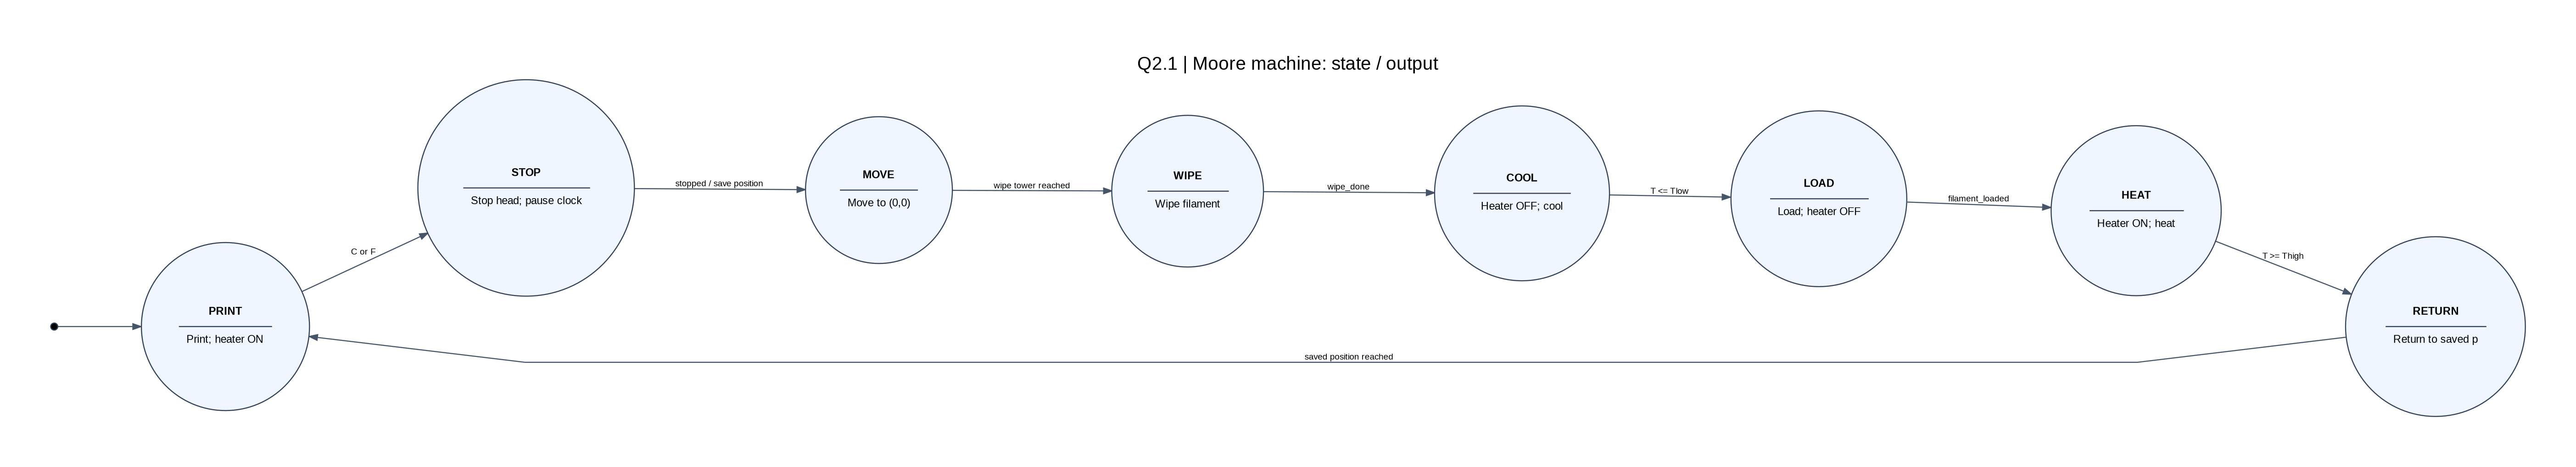

,State,Output (Moore)
0,PRINT,Print; heater ON
1,STOP,Stop head; pause clock
2,MOVE,"Move to (0,0)"
3,WIPE,Wipe filament
4,COOL,Heater OFF; cool
5,LOAD,Load; heater OFF
6,HEAT,Heater ON; heat
7,RETURN,Return to saved p


In [ ]:
# Moore convention: circular nodes divided into two compartments.
MOORE_OUTPUT = {
    'PRINT': 'Print; heater ON',
    'STOP': 'Stop head; pause clock',
    'MOVE': 'Move to (0,0)',
    'WIPE': 'Wipe filament',
    'COOL': 'Heater OFF; cool',
    'LOAD': 'Load; heater OFF',
    'HEAT': 'Heater ON; heat',
    'RETURN': 'Return to saved p'
}
MOORE_EDGES = [
    ('PRINT','STOP','C or F'),
    ('STOP','MOVE','stopped / save position'),
    ('MOVE','WIPE','wipe tower reached'),
    ('WIPE','COOL','wipe_done'),
    ('COOL','LOAD','T <= Tlow'),
    ('LOAD','HEAT','filament_loaded'),
    ('HEAT','RETURN','T >= Thigh'),
    ('RETURN','PRINT','saved position reached')
]
diagram({k:k+'\n'+v for k,v in MOORE_OUTPUT.items()}, MOORE_EDGES,
        'Q2.1 | Moore machine: state / output',initial='PRINT',rankdir='LR',moore=True)
display(pd.DataFrame([{'State':k,'Output (Moore)':v} for k,v in MOORE_OUTPUT.items()]))

The completion signals are supplied by the corresponding sensors or conditions. In this Moore machine, the outputs depend on the current state, not directly on the incoming event.

In [ ]:
def moore_step(state, event):
    rules = {('PRINT','C'):'STOP',('PRINT','F'):'STOP',
             ('STOP','stopped'):'MOVE',('MOVE','at_tower'):'WIPE',
             ('WIPE','wipe_done'):'COOL',('COOL','temperature_low'):'LOAD',
             ('LOAD','loaded'):'HEAT',('HEAT','temperature_high'):'RETURN',
             ('RETURN','returned'):'PRINT'}
    return rules.get((state,event),state)

events = ['C','stopped','at_tower','wipe_done','temperature_low',
          'loaded','temperature_high','returned']
trace=['PRINT']
for ev in events: trace.append(moore_step(trace[-1],ev))
assert trace[-1]=='PRINT' and len(trace)==9
print('Event trace:')
for i,s in enumerate(trace): print(f'{i:2d}. {s}')

Event trace:
 0. PRINT
 1. STOP
 2. MOVE
 3. WIPE
 4. COOL
 5. LOAD
 6. HEAT
 7. RETURN
 8. PRINT


# 2.2 Parked-position automaton

The observed symbols are $\Sigma=\{(H,+),(H,0),(V,+),(V,0)\}$. The automaton stores whether the horizontal and vertical end stops have been confirmed. A zero-motion observation is interpreted as reaching the corresponding end stop **only while that axis is being driven toward it**. This requires the axis to be commanded toward its end stop.

| State | Horizontal stop | Vertical stop | Interpretation |
|:--|:--:|:--:|:--|
| $q_0$ | No | No | Neither stop confirmed |
| $q_H$ | Yes | No | Horizontal stop confirmed |
| $q_V$ | No | Yes | Vertical stop confirmed |
| $q_P$ | Yes | Yes | Parked; accepting state |

A zero-motion observation sets the corresponding completion flag. A new positive-motion observation clears that axis's flag, since the motor has started moving again. The other axis's flag is unchanged. Thus the four states are sufficient for the **two completion flags**, provided the commanded-motion assumption above holds. The horizontal and vertical observations can be interleaved in any order.

In the diagram, black arrows indicate end-stop confirmation or unchanged completion status. The dashed orange arrows indicate **restarting an axis that was previously considered complete**. Both sets of arrows are part of the same automaton; the colours only distinguish their meaning.

In [ ]:
# Completion flags: (horizontal, vertical).
PARKED_STATES = {'q0': (False, False), 'qH': (True, False),
                 'qV': (False, True), 'qP': (True, True)}

def parked_step(state, symbol):
    h, v = PARKED_STATES[state]
    axis, motion = symbol
    if axis == 'H':
        h = motion == '0'
    elif axis == 'V':
        v = motion == '0'
    else:
        raise ValueError('Unknown axis')
    return next(q for q, flags in PARKED_STATES.items() if flags == (h, v))

example = [('H','+'),('V','+'),('H','+'),('H','0'),('V','+'),('V','0')]
state='q0'; example_trace=[state]
for symbol in example:
    state = parked_step(state, symbol)
    example_trace.append(state)
assert state == 'qP'
print('Input sequence:', ' '.join(f'({a},{m})' for a,m in example))
print('State sequence:', ' -> '.join(example_trace))
print('Accepted:', state == 'qP')

Input sequence: (H,+) (V,+) (H,+) (H,0) (V,+) (V,0)
State sequence: q0 -> q0 -> q0 -> q0 -> qH -> qH -> qP
Accepted: True


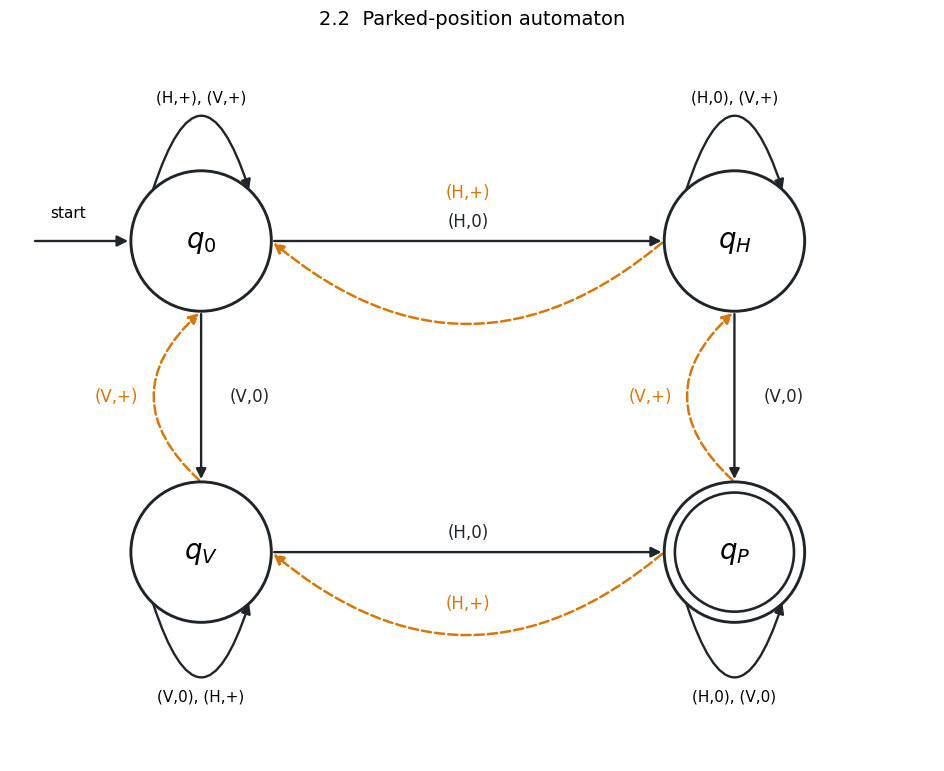

,"(H,+)","(H,0)","(V,+)","(V,0)",Accepting
State,,,,,
q0,q0,qH,q0,qV,False
qH,q0,qH,qH,qP,False
qV,qV,qP,q0,qV,False
qP,qV,qP,qH,qP,True


In [ ]:
# Four-state automaton. Layout follows the square arrangement of q0, qH, qV and qP.
# Solid: completion / unchanged status. Dashed: restart of a completed axis.
from matplotlib.patches import FancyArrowPatch, Circle

fig, ax = plt.subplots(figsize=(10.5, 7.6), layout='constrained')
ax.set_aspect('equal'); ax.axis('off')
pos = {'q0':(0,3.5), 'qH':(6,3.5), 'qV':(0,0), 'qP':(6,0)}
rad = 0.79

def draw_arrow(start, end, label, color='#20252b', style='solid', rad_curve=0.,
               label_offset=(0,0), width=1.7):
    x1,y1=pos[start];x2,y2=pos[end]
    dx,dy=x2-x1,y2-y1; length=np.hypot(dx,dy)
    u=np.array([dx,dy])/length
    a=np.array([x1,y1])+rad*u
    b=np.array([x2,y2])-rad*u
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=15,
                   linewidth=width,color=color,linestyle=style,
                   connectionstyle=f'arc3,rad={rad_curve}',zorder=2))
    mid=(a+b)/2
    off=np.array(label_offset)
    ax.text(*(mid+off),label,ha='center',va='center',fontsize=12,color=color,
            bbox=dict(facecolor='white',edgecolor='none',pad=1.3),zorder=5)

def draw_loop(key, label, direction='up'):
    x,y=pos[key]; sign=1 if direction=='up' else -1
    a=(x-.55,y+sign*.55); b=(x+.55,y+sign*.55)
    ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=14,
                 connectionstyle=f'arc3,rad={-sign*1.55}',linewidth=1.7,color='#20252b',zorder=2))
    ax.text(x,y+sign*1.62,label,ha='center',va='center',fontsize=11,
            bbox=dict(facecolor='white',edgecolor='none',pad=1.1),zorder=5)

# Completion transitions
for args in [ ('q0','qH','(H,0)',(0,.22)), ('q0','qV','(V,0)',(.55,0)),
              ('qH','qP','(V,0)',(.55,0)), ('qV','qP','(H,0)',(0,.22)) ]:
    draw_arrow(args[0],args[1],args[2],label_offset=args[3])
# Unchanged observations
for key,label,direction in [
    ('q0','(H,+), (V,+)','up'),
    ('qH','(H,0), (V,+)','up'),
    ('qV','(V,0), (H,+)','down'),
    ('qP','(H,0), (V,0)','down')]:
    draw_loop(key,label,direction)
# Restart transitions: four dashed arcs, including qP -> qV (missing in the earlier sketch).
orange='#d97706'
for a,b,lab,curve,offset in [
    ('qH','q0','(H,+)',-.42,(0,.55)),
    ('qV','q0','(V,+)',-.55,(-.95,0)),
    ('qP','qH','(V,+)',-.55,(-.95,0)),
    ('qP','qV','(H,+)',-.42,(0,-.58))]:
    draw_arrow(a,b,lab,color=orange,style='dashed',rad_curve=curve,
               label_offset=offset,width=1.8)
# Nodes on top of edges
for key,(x,y) in pos.items():
    ax.add_patch(Circle((x,y),rad,facecolor='white',edgecolor='#20252b',lw=2.1,zorder=6))
    if key=='qP':
        ax.add_patch(Circle((x,y),rad-.12,facecolor='none',edgecolor='#20252b',lw=1.9,zorder=7))
    ax.text(x,y,{'q0':r'$q_0$','qH':r'$q_H$','qV':r'$q_V$','qP':r'$q_P$'}[key],
            fontsize=20,ha='center',va='center',zorder=8)
ax.annotate('',xy=(-rad,3.5),xytext=(-1.9,3.5),
            arrowprops=dict(arrowstyle='-|>',mutation_scale=16,lw=1.7,color='#20252b'))
ax.text(-1.7,3.77,'start',fontsize=11)
ax.set_xlim(-2.15,8.25);ax.set_ylim(-2.35,5.75)
ax.set_title('2.2  Parked-position automaton',fontsize=14,pad=12)
plt.show()

transition_rows=[]
for q in PARKED_STATES:
    row={'State':q}
    for sym in [('H','+'),('H','0'),('V','+'),('V','0')]:
        row[f'({sym[0]},{sym[1]})']=parked_step(q,sym)
    row['Accepting']=q=='qP'
    transition_rows.append(row)
display(pd.DataFrame(transition_rows).set_index('State'))

The accepting state is $q_P$. For the sequence specified in the assignment,

$$(H,+)(V,+)(H,+)(H,0)(V,+)(V,0),$$

the state sequence is $q_0\to q_0\to q_0\to q_0\to q_H\to q_H\to q_P$. Both end stops are confirmed, so the sequence is accepted. The orange transitions ensure that the parked state is not retained if either motor subsequently moves away from its confirmed stop.